# 14 · Decisions on the validation episodes

The latent fit holds out one fifth of the transition log. Those episode ids are `val_episodes` in `runs/jepa-replenishment/checkpoints/planner.json`. This notebook replays that holdout and, on every observation, records the order the latent planner would send and the order each textbook rule would send.

The shop is the buyer that wrote the episode (`log_buyer`), with the collector's factory policies (`_factory_overrides`). Cash, on-hand, in-transit, sales, and fills are that held-out sequence. `ReplenishmentPlanner.decide` and the textbook `decide` calls read the same observation and return without changing the order the runner places. A fresh planner comes from `retarget`, which keeps the fitted weights and clears `sales_log`.

The textbook columns are the four classes `compare_synthetic` scores, plus `anchor`, the order-up-to rule tuned at holding rate 0.01. The logged buyer is whichever mixture arm drew that episode. A validation episode can be exploratory or over-order.

Imagined arrivals use `apply_logged_fill_rate` on this log, the same call `score_rollout_gate` makes before a profit table. The rate is the share of textbook orders that Allocation filled. The checkpoint still stores the older ratio over every behavior, including over-order, which is about 0.0015. Under that ratio a cover imagines an empty arrival, the search keeps cover 0, and `jepa_requested` is zero on every row.

One episode takes about five minutes. The planner runs a cover search on every tick, and a validation shop carries around thirty products. `SEEDS` chooses the episodes. A seed already written under `runs/jepa-replenishment/validation-decisions/` is loaded instead of rolled again. A frame collected before this fill-rate correction is stale; delete it or set `RECOMPUTE = True`.


In [1]:
import json
import os
from pathlib import Path

import pandas as pd

while not (Path.cwd() / "pyproject.toml").exists():
    os.chdir("..")

from src.jepa.commands import _order_up_to_factory, order_up_to_study_name
from src.jepa.dynamics import apply_logged_fill_rate
from src.jepa.eval import IN_DISTRIBUTION_HOLDING_RATE
from src.jepa.log import (
    _annotate_steps,
    _factory_overrides,
    _snapshot,
    build_log_scenario,
    collection_config,
    log_buyer,
)
from src.jepa.plan import load_planners
from src.sim.policy import (
    IntermediatePolicy,
    OrderUpToPolicy,
    PeriodicOrderUpToPolicy,
    PeriodicReorderPolicy,
    ReorderPointPolicy,
)
from src.sim.runner import Runner
from src.tuning.episode import make_synthetic_catalog, partition_catalog
from src.tuning.search_spaces import order_up_to_from_params

CHECKPOINTS = Path("runs/jepa-replenishment/checkpoints")
LOG_PATH = Path("runs/jepa-replenishment/log/transitions.parquet")
MANIFEST_PATH = Path("runs/jepa-replenishment/log/transitions.manifest.json")
CACHE = Path("runs/jepa-replenishment/validation-decisions")

if not (CHECKPOINTS / "planner.json").is_file():
    raise FileNotFoundError(
        f"{CHECKPOINTS / 'planner.json'} is missing. The published fit command is in the root README."
    )
if not MANIFEST_PATH.is_file() or not LOG_PATH.is_file():
    raise FileNotFoundError(
        f"{LOG_PATH} is missing. The published collect command is in the root README."
    )

# Recorded best_params for holding rate 0.01 in docs/jepa-replenishment.md.
# Used when the tuning study file is absent. runs/ is gitignored.
PUBLISHED_ANCHOR_001 = {
    "cover_horizon_ticks": 12,
    "safety_lead_pct_of_lag": 0.16993287200409285,
    "stockout_safety_bonus_pct_of_lag": 0.09706576917593086,
}

latent, _direct = load_planners(CHECKPOINTS)
fill_frame = pd.read_parquet(
    LOG_PATH, columns=["behavior", "requested_qty", "filled_qty"]
)
fill_rate = apply_logged_fill_rate(latent.dynamics, fill_frame)
apply_logged_fill_rate(_direct.dynamics, fill_frame)
del fill_frame
print(f"imagined fill rate {fill_rate:.6f} from textbook orders in the log")
manifest = json.loads(MANIFEST_PATH.read_text())
behavior_of = {
    int(hyper["episode_seed"]): arm["behavior"]
    for arm in manifest["behavior_mixture"]
    for hyper in arm["hyperparameters"]
}
val_seeds = sorted(int(seed) for seed in latent.dynamics.val_episodes)
missing = [seed for seed in val_seeds if seed not in behavior_of]
if missing:
    raise KeyError(f"validation seeds missing from the log manifest: {missing[:5]}")

config = collection_config(holding_rate=float(latent.holding_rate))
catalog, _evaluation = partition_catalog(make_synthetic_catalog(config.active_catalog_size()))

study_dir = Path("runs/jepa-replenishment/tuning") / order_up_to_study_name(
    IN_DISTRIBUTION_HOLDING_RATE
)
if (study_dir / "study.json").is_file():
    anchor_factory = _order_up_to_factory(study_dir, IN_DISTRIBUTION_HOLDING_RATE)
    print("anchor from", study_dir / "study.json")
else:

    def anchor_factory():
        return order_up_to_from_params(PUBLISHED_ANCHOR_001)

    print("anchor from docs/jepa-replenishment.md best_params")

val_index = pd.DataFrame(
    {
        "episode_seed": val_seeds,
        "logged_behavior": [behavior_of[seed] for seed in val_seeds],
    }
)
print(f"{len(val_index)} validation episodes")
print(val_index["logged_behavior"].value_counts().to_string())
val_index


imagined fill rate 0.999647 from textbook orders in the log
anchor from runs/jepa-replenishment/tuning/order_up_to_holding_0_01/study.json
179 validation episodes
logged_behavior
over_order              105
exploratory              19
order_up_to              15
reorder_point            15
periodic_order_up_to     10
never_order               8
periodic_reorder          7


,episode_seed,logged_behavior
0,14000002,order_up_to
1,14000008,order_up_to
2,14000010,order_up_to
3,14000011,order_up_to
4,14000026,order_up_to
...,...,...
174,14000874,over_order
175,14000879,over_order
176,14000886,over_order
177,14000889,over_order


## The decision frame

`collect_seed` rebuilds the episode with `build_log_scenario` and runs it once. Each row is one product on one tick. The last tick is omitted, as in the transition log, because it has no next observation.

`logged_requested` and `logged_filled` are the order the runner placed. `jepa_requested` is the latent planner's order on that observation, and `jepa_cover` is the cover the search chose for that product. `jepa_score` is the imagined return of the chosen proposal, one number for the whole shop on that tick. `anchor_requested` and the four `*_requested` textbook columns are the same kind of counterfactual. `sold` is units sold on that tick. `in_transit` is the pipeline at the decision, summed across arrival ages. `cash` and `capacity` are the shop, repeated on every product row.


In [2]:
def order_units(action, pid):
    """Units requested for one SKU, summed across suppliers."""
    lines = (action.get("order") or {}).get(pid) or []
    return sum(int(qty) for _supplier, qty in lines)


class DecisionLog(IntermediatePolicy):
    """One buyer drives the shop. The other rules decide on the same observation."""

    def __init__(self, driver, others, episode_seed):
        super().__init__(policy_seed=getattr(driver, "policy_seed", None))
        self.driver = driver
        self.others = others
        self.episode_seed = int(episode_seed)
        self._sales = {}
        self.steps = []

    def decide(self, obs, table):
        actions = {
            name: policy.decide(obs, table) for name, policy in self.others.items()
        }
        driver_action = self.driver.decide(obs, table)
        step = _snapshot(obs, driver_action, self._sales)
        planner = self.others["jepa"] if "jepa" in self.others else self.driver
        proposal = planner.proposals[-1]
        covers = proposal["chosen"]["covers"]
        score = proposal["score"]
        for pid, snap in step.items():
            for name, action in actions.items():
                snap[f"{name}_requested"] = order_units(action, pid)
            if "jepa" not in actions:
                snap["jepa_requested"] = int(snap["requested_qty"])
            snap["jepa_cover"] = int(covers.get(pid, 0))
            snap["jepa_score"] = None if score is None else float(score)
        self.steps.append(step)
        tick = int(obs.get("tick") or 0)
        if tick == 1 or tick % 50 == 0:
            print(f"seed {self.episode_seed} tick {tick}", flush=True)
        return driver_action


def rows_from_steps(steps, episode_seed, behavior):
    """One product-tick row. The last step has no next observation, so it is dropped."""
    rows = []
    for index in range(len(steps) - 1):
        current = steps[index]
        nxt = steps[index + 1]
        for pid, cur in current.items():
            if pid not in nxt:
                continue
            transit = cur["in_transit"]
            in_transit = int(sum(transit)) if isinstance(transit, (list, tuple)) else int(transit)
            rows.append(
                {
                    "episode_seed": int(episode_seed),
                    "logged_behavior": behavior,
                    "tick": int(cur["tick"]),
                    "product_id": pid,
                    "on_hand": int(cur["on_hand"]),
                    "in_transit": in_transit,
                    "sold": int(cur["sales"]),
                    "cash": float(cur["cash"]),
                    "capacity": int(cur["capacity"]),
                    "logged_requested": int(cur["requested_qty"]),
                    "logged_filled": int(cur["filled_qty"]),
                    "jepa_requested": int(cur["jepa_requested"]),
                    "jepa_cover": int(cur["jepa_cover"]),
                    "jepa_score": (
                        float("nan") if cur["jepa_score"] is None else float(cur["jepa_score"])
                    ),
                    "anchor_requested": int(cur["anchor_requested"]),
                    "order_up_to_requested": int(cur["order_up_to_requested"]),
                    "reorder_point_requested": int(cur["reorder_point_requested"]),
                    "periodic_order_up_to_requested": int(cur["periodic_order_up_to_requested"]),
                    "periodic_reorder_requested": int(cur["periodic_reorder_requested"]),
                    "next_on_hand": int(nxt[pid]["on_hand"]),
                    "next_sales": int(nxt[pid]["sales"]),
                }
            )
    return pd.DataFrame(rows)


def _check_against_log(frame, seed):
    """The logged columns are the transition log for this seed."""
    if not LOG_PATH.is_file():
        print(f"{LOG_PATH} is missing, so the replay was not checked against the log")
        return
    logged = pd.read_parquet(LOG_PATH, filters=[("episode_seed", "==", int(seed))])
    logged = logged.sort_values(["product_id", "tick"]).reset_index(drop=True)
    fresh = frame.sort_values(["product_id", "tick"]).reset_index(drop=True)
    if len(logged) != len(fresh):
        raise AssertionError(
            f"replay row count {len(fresh)} != log {len(logged)} at seed {seed}"
        )
    pairs = (
        ("on_hand", "on_hand"),
        ("requested_qty", "logged_requested"),
        ("filled_qty", "logged_filled"),
        ("cash", "cash"),
    )
    for log_column, frame_column in pairs:
        if not (logged[log_column].to_numpy() == fresh[frame_column].to_numpy()).all():
            raise AssertionError(f"replay diverged on {log_column} at seed {seed}")


def collect_seed(seed, recompute=False, driver="logged"):
    """Decision rows for one validation episode.

    ``driver="logged"`` lets the original mixture arm place the orders.
    ``driver="jepa"`` lets the latent planner place them. The textbook
    rules are asked on the same observation either way. A JEPA-driven
    episode is cached as ``<seed>-jepa.parquet`` and is not checked
    against the transition log.
    """
    seed = int(seed)
    if driver not in {"logged", "jepa"}:
        raise ValueError(f"driver must be 'logged' or 'jepa', got {driver!r}")
    if seed not in behavior_of:
        raise KeyError(f"seed {seed} is not in the log manifest")
    path = CACHE / (f"{seed}.parquet" if driver == "logged" else f"{seed}-jepa.parquet")
    if path.is_file() and not recompute:
        print(f"seed {seed} loaded from {path}")
        return pd.read_parquet(path)

    spec = build_log_scenario(config, seed, catalog)
    textbooks = {
        "anchor": anchor_factory(),
        "order_up_to": OrderUpToPolicy(),
        "reorder_point": ReorderPointPolicy(),
        "periodic_order_up_to": PeriodicOrderUpToPolicy(),
        "periodic_reorder": PeriodicReorderPolicy(),
    }
    if driver == "logged":
        behavior = behavior_of[seed]
        shop, _hyper = log_buyer(behavior, seed, spec.delivery_lag)
        others = {"jepa": latent.retarget(latent.holding_rate), **textbooks}
    else:
        behavior = "jepa"
        shop = latent.retarget(latent.holding_rate)
        others = textbooks
    viewer = DecisionLog(shop, others, seed)
    overrides = _factory_overrides(spec.scenario)
    overrides["S"] = viewer
    run_log = Runner(spec.scenario, policy_overrides=overrides).run()
    _annotate_steps(viewer.steps, run_log, spec.scenario, "S", spec.delivery_lag)
    frame = rows_from_steps(viewer.steps, seed, behavior)
    if driver == "logged":
        _check_against_log(frame, seed)
    CACHE.mkdir(parents=True, exist_ok=True)
    frame.to_parquet(path, index=False)
    print(f"seed {seed} wrote {path} ({len(frame)} rows)")
    return frame


# Validation episodes to roll. Each uncached seed takes about five minutes.
# val_seeds is the full holdout. RECOMPUTE rolls a cached seed again.
SEEDS = val_seeds[:1]
RECOMPUTE = False

decisions = pd.concat(
    [collect_seed(seed, recompute=RECOMPUTE) for seed in SEEDS],
    ignore_index=True,
)
print(
    f"{len(decisions)} rows, {decisions['episode_seed'].nunique()} episodes, "
    f"ticks {int(decisions['tick'].min())} through {int(decisions['tick'].max())}"
)
decisions.head()


seed 14000002 loaded from runs/jepa-replenishment/validation-decisions/14000002.parquet
10192 rows, 1 episodes, ticks 1 through 364


,episode_seed,logged_behavior,tick,product_id,on_hand,in_transit,sold,cash,capacity,logged_requested,...,jepa_requested,jepa_cover,jepa_score,anchor_requested,order_up_to_requested,reorder_point_requested,periodic_order_up_to_requested,periodic_reorder_requested,next_on_hand,next_sales
0,14000002,order_up_to,1,P0000,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0
1,14000002,order_up_to,1,P0034,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0
2,14000002,order_up_to,1,P0059,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,212,1
3,14000002,order_up_to,1,P0077,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0
4,14000002,order_up_to,1,P0109,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0


## JEPA drives the shop

`collect_seed(seed, driver="jepa")` rebuilds the same validation episode. Demand and the opening shop match the held-out log. The latent planner is the buyer the simulator fills, so `on_hand`, `in_transit`, `sold`, `cash`, `logged_requested`, and `logged_filled` are JEPA's year. `logged_behavior` is `jepa`. `jepa_requested` is the same order as `logged_requested`.

The textbook columns are still computed on that observation and not sent to the supplier. The cache file is `<seed>-jepa.parquet` next to the original buyer's file. This run is not checked against the transition log, because the shop no longer follows it.

Each uncached seed takes about five minutes. `SEEDS` and `RECOMPUTE` are the knobs in the cell above.


In [3]:
jepa_decisions = pd.concat(
    [collect_seed(seed, recompute=RECOMPUTE, driver="jepa") for seed in SEEDS],
    ignore_index=True,
)
print(
    f"{len(jepa_decisions)} rows, behavior {jepa_decisions['logged_behavior'].unique().tolist()}, "
    f"ticks {int(jepa_decisions['tick'].min())} through {int(jepa_decisions['tick'].max())}"
)
print(
    "jepa units ordered",
    int(jepa_decisions["logged_requested"].sum()),
    "on",
    int((jepa_decisions["logged_requested"] > 0).sum()),
    "product-days",
)
jepa_decisions.head()


seed 14000002 tick 1
seed 14000002 tick 50
seed 14000002 tick 100
seed 14000002 tick 150
seed 14000002 tick 200
seed 14000002 tick 250
seed 14000002 tick 300
seed 14000002 tick 350
seed 14000002 wrote runs/jepa-replenishment/validation-decisions/14000002-jepa.parquet (10192 rows)
10192 rows, behavior ['jepa'], ticks 1 through 364
jepa units ordered 735 on 40 product-days


,episode_seed,logged_behavior,tick,product_id,on_hand,in_transit,sold,cash,capacity,logged_requested,...,jepa_requested,jepa_cover,jepa_score,anchor_requested,order_up_to_requested,reorder_point_requested,periodic_order_up_to_requested,periodic_reorder_requested,next_on_hand,next_sales
0,14000002,jepa,1,P0000,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0
1,14000002,jepa,1,P0034,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0
2,14000002,jepa,1,P0059,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,212,1
3,14000002,jepa,1,P0077,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0
4,14000002,jepa,1,P0109,213,0,0,129861.209713,15996,0,...,0,0,87544.385052,0,0,0,0,0,213,0


## One product

`plot_product` draws one product of one validation episode. On-hand and in-transit are the pipeline at the decision. Sold is that tick. The order panel is units requested: the logged buyer, the latent planner, and the tuned order-up-to anchor. The other textbook columns are in `decisions` and can be added to `order_columns`. Cash is the shop.


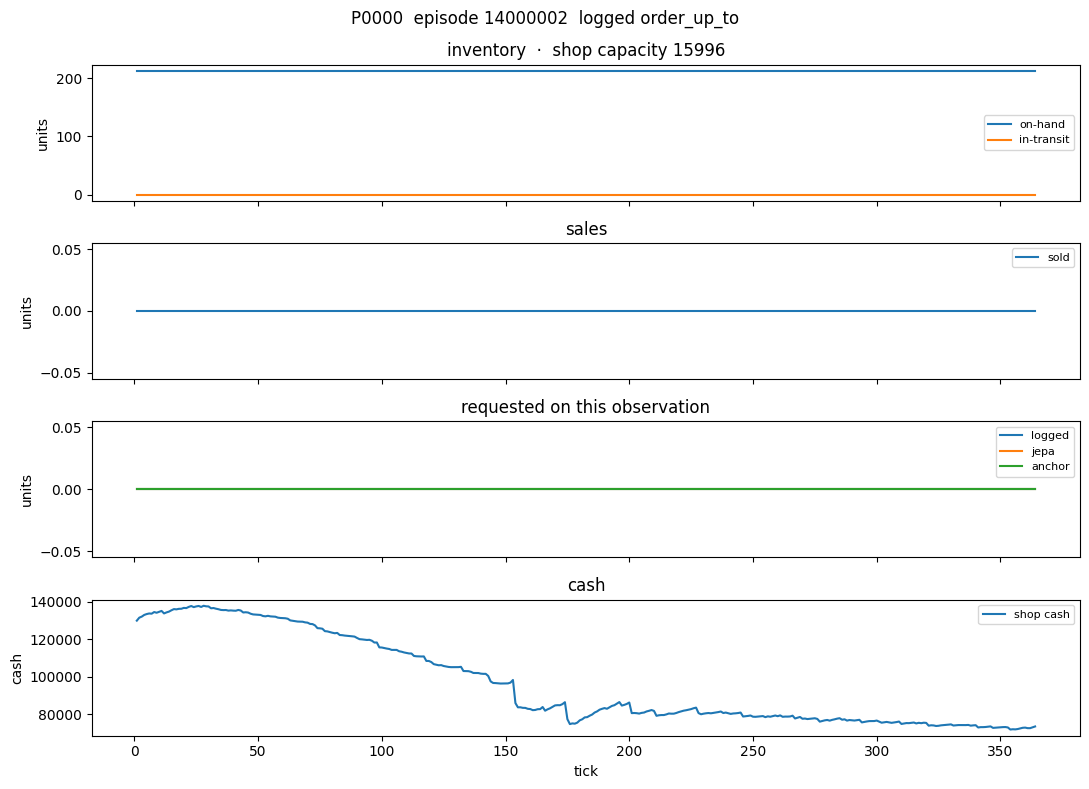

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt


def plot_product(frame, episode_seed, product_id, order_columns=None):
    """State and requested units for one product in one validation episode."""
    sku = frame.loc[
        (frame["episode_seed"] == int(episode_seed)) & (frame["product_id"] == product_id)
    ].sort_values("tick")
    if sku.empty:
        raise KeyError(f"no rows for episode {episode_seed} product {product_id}")
    columns = order_columns or (
        "logged_requested",
        "jepa_requested",
        "anchor_requested",
    )
    tick = sku["tick"].to_numpy()
    behavior = sku["logged_behavior"].iloc[0]

    fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
    fig.suptitle(f"{product_id}  episode {int(episode_seed)}  logged {behavior}")

    axes[0].plot(tick, sku["on_hand"], label="on-hand")
    axes[0].plot(tick, sku["in_transit"], label="in-transit")
    axes[0].set_ylabel("units")
    axes[0].set_title(f"inventory  ·  shop capacity {int(sku['capacity'].iloc[0])}")
    axes[0].legend(fontsize=8)

    axes[1].step(tick, sku["sold"], where="mid", label="sold")
    axes[1].set_ylabel("units")
    axes[1].set_title("sales")
    axes[1].legend(fontsize=8)

    for column in columns:
        axes[2].step(tick, sku[column], where="mid", label=column.removesuffix("_requested"))
    axes[2].set_ylabel("units")
    axes[2].set_title("requested on this observation")
    axes[2].legend(fontsize=8)

    axes[3].plot(tick, sku["cash"], label="shop cash")
    axes[3].set_ylabel("cash")
    axes[3].set_xlabel("tick")
    axes[3].set_title("cash")
    axes[3].legend(fontsize=8)

    fig.tight_layout()
    plt.close(fig)
    return fig


example_seed = int(decisions["episode_seed"].iloc[0])
example_product = sorted(decisions.loc[decisions["episode_seed"] == example_seed, "product_id"].unique())[0]
plot_product(decisions, example_seed, example_product)


In [5]:
decisions.groupby('product_id').agg({'sold': 'mean', 'logged_requested': 'mean', 
'logged_filled': 'mean', 
'jepa_requested': 'mean', 
'anchor_requested': 'mean', 
'order_up_to_requested': 'mean', 
'reorder_point_requested': 'mean', 
'periodic_order_up_to_requested': 'mean', 
'periodic_reorder_requested': 'mean'}).sort_values('jepa_requested', ascending=False)

,sold,logged_requested,logged_filled,jepa_requested,anchor_requested,order_up_to_requested,reorder_point_requested,periodic_order_up_to_requested,periodic_reorder_requested
product_id,,,,,,,,,
P0677,6.417582,6.010989,6.010989,1.142857,0.346154,0.420330,0.346154,13.640110,0.000000
P0450,5.733516,5.266484,5.266484,0.557692,0.000000,0.000000,0.000000,5.098901,0.000000
P0294,1.791209,1.255495,1.255495,0.326923,0.000000,0.000000,0.000000,3.552198,0.000000
P0554,1.722527,1.167582,1.167582,0.241758,0.000000,0.000000,0.000000,2.741758,0.000000
P0600,3.508242,2.945055,2.945055,0.200549,0.000000,0.000000,0.000000,4.002747,0.000000
P0337,1.703297,1.230769,1.230769,0.195055,0.000000,0.252747,0.250000,3.381868,0.252747
P0287,1.728022,1.200549,1.200549,0.186813,0.000000,0.000000,0.000000,2.700549,0.000000
P0406,1.417582,0.914835,0.914835,0.129121,0.000000,0.000000,0.000000,2.126374,0.000000
P0312,0.782967,0.230769,0.230769,0.041209,0.000000,0.000000,0.000000,0.791209,0.000000


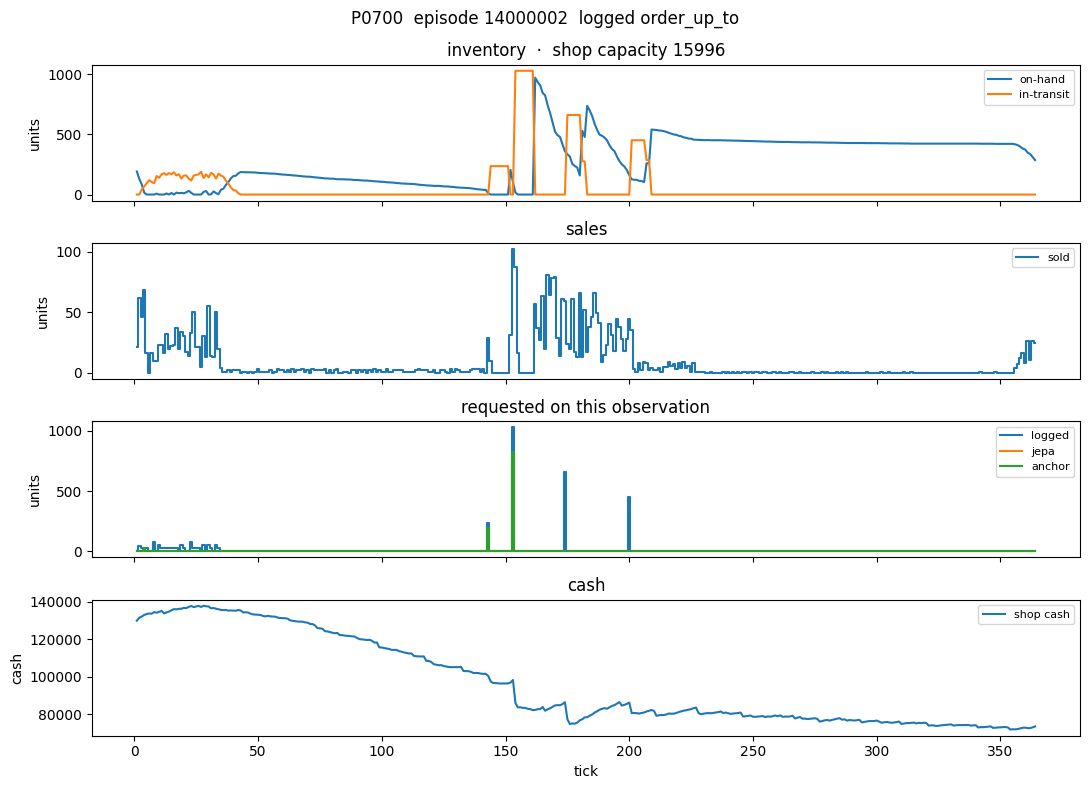

In [6]:
plot_product(decisions, example_seed, "P0700")

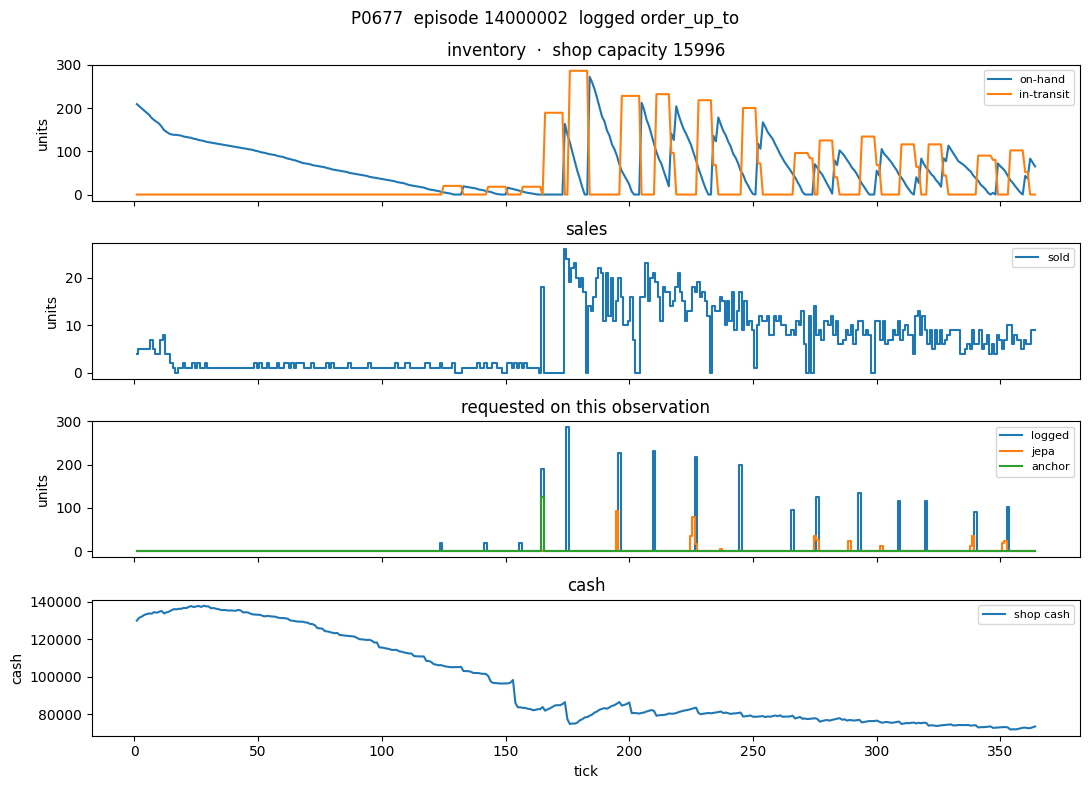

In [7]:
plot_product(decisions, example_seed, "P0677")


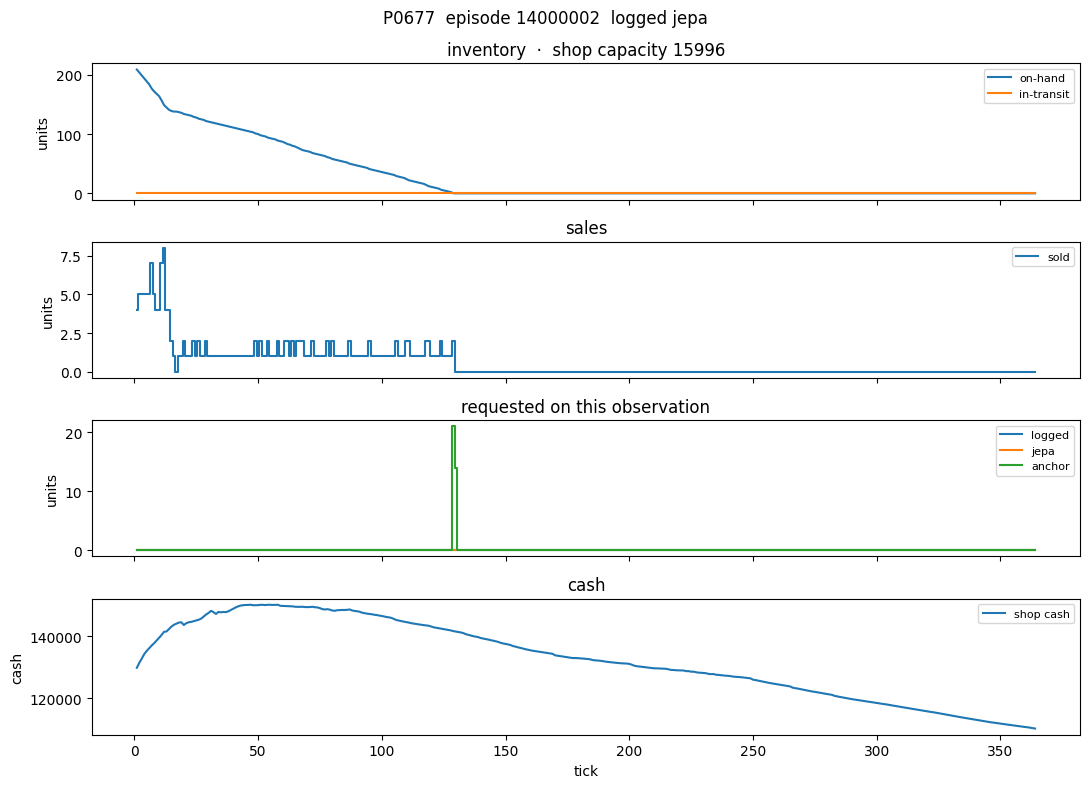

In [11]:
plot_product(jepa_decisions, example_seed, "P0677")


## Cash, stock, and sales

Bands are tertiles of the rows in `decisions`. Cash is cut on shop-ticks, so a tick counts once however many products it carries. Stock is on-hand plus in-transit, and sales are units sold on that tick; both are cut on product-ticks. The table is the mean units each policy requested inside the band. `logged_filled` is what the shop actually received.


In [8]:
REQUESTS = [
    "logged_requested",
    "logged_filled",
    "jepa_requested",
    "anchor_requested",
    "order_up_to_requested",
    "reorder_point_requested",
    "periodic_order_up_to_requested",
    "periodic_reorder_requested",
]


def _tertile(values):
    """Low, mid, and high. A series with too many ties stays one band."""
    series = pd.Series(values)
    if series.nunique(dropna=True) < 3:
        return pd.Series(["mid"] * len(series), index=series.index)
    try:
        bands = pd.qcut(series, 3, labels=["low", "mid", "high"], duplicates="drop")
    except ValueError:
        return pd.Series(["mid"] * len(series), index=series.index)
    return bands.astype(str)


def with_bands(frame):
    """Copy of ``frame`` with cash, stock, and sales bands."""
    out = frame.copy()
    ticks = (
        out.groupby(["episode_seed", "tick"], sort=False)["cash"]
        .first()
        .reset_index()
    )
    ticks["cash_band"] = _tertile(ticks["cash"])
    out = out.merge(ticks[["episode_seed", "tick", "cash_band"]], on=["episode_seed", "tick"])
    out["stock"] = out["on_hand"] + out["in_transit"]
    out["stock_band"] = _tertile(out["stock"])
    out["sales_band"] = _tertile(out["sold"])
    return out


def mean_requests(frame, band):
    grouped = frame.groupby(band, sort=False)[REQUESTS].mean()
    order = [label for label in ("low", "mid", "high") if label in grouped.index]
    return grouped.reindex(order)


banded = with_bands(decisions)
print(
    "cash cuts",
    banded.groupby("cash_band")["cash"].agg(["min", "max"]).reindex(["low", "mid", "high"]),
)
print("mean requested units by shop-cash tertile")
mean_requests(banded, "cash_band")


cash cuts                      min            max
cash_band                              
low         71767.603069   78914.106773
mid         78943.154149  106330.257370
high       106655.130056  137798.791762
mean requested units by shop-cash tertile


,logged_requested,logged_filled,jepa_requested,anchor_requested,order_up_to_requested,reorder_point_requested,periodic_order_up_to_requested,periodic_reorder_requested
cash_band,,,,,,,,
low,0.637002,0.637002,0.130562,0.000000,0.000000,0.000000,1.500585,0.000000
mid,1.786305,1.786305,0.136954,0.352420,0.463695,0.413223,3.443329,0.028335
high,1.242621,1.242621,0.059327,0.007674,0.051948,0.051653,1.797226,0.035714


In [9]:
print("mean requested units by stock tertile (on-hand + in-transit)")
mean_requests(banded, "stock_band")


mean requested units by stock tertile (on-hand + in-transit)


,logged_requested,logged_filled,jepa_requested,anchor_requested,order_up_to_requested,reorder_point_requested,periodic_order_up_to_requested,periodic_reorder_requested
stock_band,,,,,,,,
low,2.003231,2.003231,0.184783,0.107521,0.188308,0.166275,2.839600,0.056110
mid,1.376458,1.376458,0.133815,0.237091,0.307052,0.280122,2.355081,0.007218
high,0.207470,0.207470,0.000000,0.000000,0.000000,0.000000,1.485248,0.000000


In [10]:
print("mean requested units by sales tertile")
mean_requests(banded, "sales_band")


mean requested units by sales tertile


,logged_requested,logged_filled,jepa_requested,anchor_requested,order_up_to_requested,reorder_point_requested,periodic_order_up_to_requested,periodic_reorder_requested
sales_band,,,,,,,,
mid,1.220369,1.220369,0.109007,0.119702,0.171409,0.154533,2.244996,0.021291
